# MedViHall: Pillars C, D and E analysis

Consolidates the saved results of the three analysis pillars into one runnable notebook.

| Section | Question | Source files (`medvihall_outputs/`) |
|---|---|---|
| 1. Core benchmark | Which of 12 VLMs hallucinate least (SMHR, CHR, SRI)? | `metrics_summary.json` |
| 2. Pillar C (RQ9) | Do CREST / MediHall Score agree with SMHR? | `pillar_c_metric_concordance.json` |
| 3. Pillar E (RQ5) | Does hallucination safety transfer across modalities? | `pillar_e_cross_modal_transfer.json` |
| 4. Pillar D (RQ10) | Is verbalized calibration a weights property or a decoding artifact? | `pillar_d_calibration_results.json`, `pillar_d_robustness.json` |

Running the notebook only reads saved results. Set `RERUN_CPU_ANALYSES = True` in the setup cell to recompute the
Pillar D ECE/ACE and robustness numbers from the saved labels (CPU, a few minutes). The GPU stages (Pillar D
generation, claim extraction, judging) are listed as commands in section 5 and are not run from here.

In [1]:
import json, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.float_format', lambda v: f'{v:.3f}')
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)

ROOT = Path.cwd()
if not (ROOT / 'medvihall_outputs').exists():
    ROOT = ROOT.parent
OUT = ROOT / 'medvihall_outputs'

RERUN_CPU_ANALYSES = False   # True: recompute Pillar D ECE/ACE + robustness (CPU only, minutes)

def load(name):
    return json.loads((OUT / name).read_text(encoding='utf-8'))

MEDICAL_COLOR, GENERAL_COLOR = '#c0392b', '#2c7fb8'
print('project root:', ROOT)

project root: C:\Users\PC\Desktop\Programs\MediViHall


## 1. Core benchmark: 12 VLMs, 141,000 responses

Pipeline: claim extraction (local Qwen2.5-7B) -> Layer 1 automated check (CheXbert for radiology, scispaCy +
negspaCy lexicons otherwise) -> Layer 2 LLM judge (7-class taxonomy) -> SMHR (severity-weighted hallucination
rate), CHR, and SRI (specialist ratio index = specialist SMHR / best general VLM SMHR in that modality).
Lower SMHR is better.

,model,medical,SMHR,CHR,SMHR_radio,SMHR_derma,SMHR_histo,SMHR_ophth
rank,,,,,,,,
1,qwen25vl,False,0.529,0.785,0.728,0.348,0.533,0.455
2,gemma3,False,0.532,0.731,0.633,0.461,0.575,0.465
3,internvl3,False,0.539,0.760,0.652,0.447,0.504,0.470
4,qwen35,False,0.549,0.773,0.675,0.496,0.482,0.416
5,qwen3vl,False,0.562,0.730,0.764,0.415,0.521,0.418
6,minicpm,False,0.580,0.715,0.619,0.533,0.646,0.442
7,idefics3,False,0.636,0.800,0.644,0.602,0.651,0.627
8,qwen2vl,False,0.643,0.797,0.828,0.435,0.564,0.571
9,llava16,False,0.675,0.741,0.746,0.565,0.716,0.571


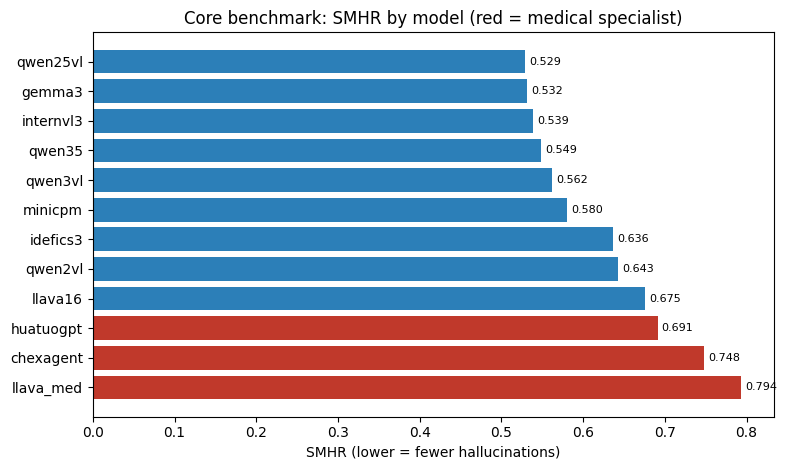

In [2]:
ms = load('metrics_summary.json')
core = pd.DataFrame([
    {'model': k, 'medical': v['is_medical'], 'SMHR': v['smhr_overall'], 'CHR': v['chr_overall'],
     **{f'SMHR_{m[:5]}': d['smhr'] for m, d in v['by_modality'].items()}}
    for k, v in ms['models'].items()
]).sort_values('SMHR').reset_index(drop=True)
core.index += 1
core.index.name = 'rank'
display(core)

fig, ax = plt.subplots(figsize=(8, 4.8))
colors = [MEDICAL_COLOR if m else GENERAL_COLOR for m in core['medical']]
ax.barh(core['model'][::-1], core['SMHR'][::-1], color=colors[::-1])
ax.set_xlabel('SMHR (lower = fewer hallucinations)')
ax.set_title('Core benchmark: SMHR by model (red = medical specialist)')
for y, v in enumerate(core['SMHR'][::-1]):
    ax.text(v + 0.005, y, f'{v:.3f}', va='center', fontsize=8)
plt.tight_layout(); plt.show()

In [3]:
sri = pd.DataFrame({sp: {mod: d['sri'] for mod, d in mods.items()} for sp, mods in ms['sri'].items()}).T
display(Markdown('**SRI per specialist per modality** (> 1 means the specialist hallucinates MORE than the best general VLM in that modality)'))
display(sri)
best = pd.DataFrame(ms['best_general_vlm_by_modality']).T
best.columns = ['best general VLM', 'its SMHR']
display(best)

**SRI per specialist per modality** (> 1 means the specialist hallucinates MORE than the best general VLM in that modality)

,dermatology,histopathology,ophthalmology,radiology
chexagent,1.810,1.528,1.748,1.335
huatuogpt,1.652,1.309,1.356,1.338
llava_med,1.855,1.545,1.608,1.488


,best general VLM,its SMHR
dermatology,qwen25vl,0.348
histopathology,qwen35,0.482
ophthalmology,qwen35,0.416
radiology,minicpm,0.619


## 2. Pillar C (RQ9): metric concordance

CREST = mean clinical-risk rating (1-3) over erroneous claims (higher = worse). MediHall Score = mean per-claim
score in [0, 1] over all claims (higher = better). If the metrics agree with SMHR, SMHR-vs-CREST should be
positive and SMHR-vs-MediHall negative.

,model,SMHR,CREST,MediHall,medical
0,qwen25vl,0.529,2.675,0.471,False
1,gemma3,0.532,2.750,0.469,False
2,internvl3,0.539,2.668,0.462,False
3,qwen35,0.549,2.765,0.451,False
4,qwen3vl,0.562,2.737,0.438,False
5,minicpm,0.580,2.747,0.419,False
6,idefics3,0.636,2.803,0.363,False
7,qwen2vl,0.643,2.772,0.358,False
8,llava16,0.675,2.759,0.325,False
9,huatuogpt,0.691,2.717,0.312,True


**Spearman correlations (overall, n=12 models):** smhr_vs_crest = +0.643, smhr_vs_medihall = -1.000, crest_vs_medihall = -0.643

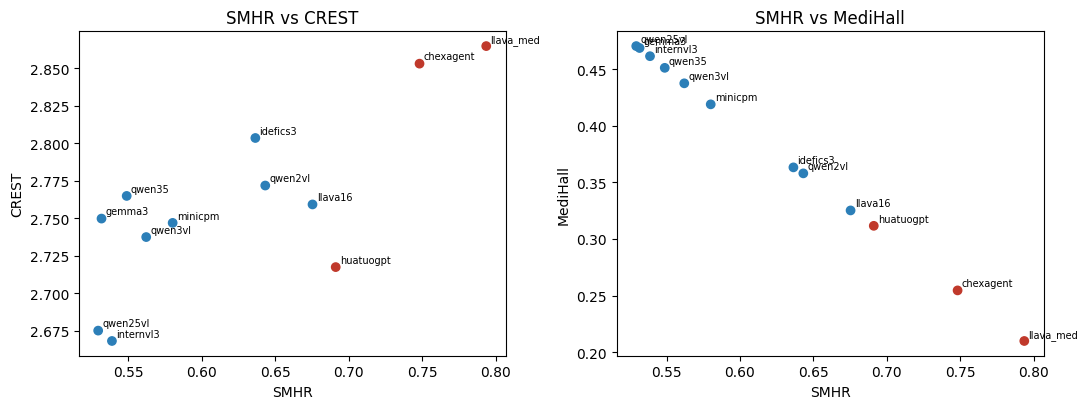

**Largest SMHR-vs-CREST divergences**

,model,modality,smhr,crest,z_diff,pattern
0,huatuogpt,ophthalmology,0.564,2.353,1.888,high SMHR-vs-CREST (frequent but comparatively...
1,qwen35,histopathology,0.482,2.781,-1.327,high CREST-vs-SMHR (rare but severe errors)
2,gemma3,radiology,0.633,2.960,-1.232,high CREST-vs-SMHR (rare but severe errors)
3,qwen3vl,dermatology,0.415,2.678,-1.229,high CREST-vs-SMHR (rare but severe errors)
4,internvl3,ophthalmology,0.470,2.347,1.195,high SMHR-vs-CREST (frequent but comparatively...
5,internvl3,histopathology,0.504,2.777,-1.131,high CREST-vs-SMHR (rare but severe errors)
6,llava16,ophthalmology,0.571,2.493,1.102,high SMHR-vs-CREST (frequent but comparatively...
7,huatuogpt,dermatology,0.574,2.507,1.044,high SMHR-vs-CREST (frequent but comparatively...
8,llava_med,radiology,0.921,2.959,1.020,high SMHR-vs-CREST (frequent but comparatively...
9,qwen2vl,radiology,0.828,2.840,1.016,high SMHR-vs-CREST (frequent but comparatively...


In [4]:
pc = load('pillar_c_metric_concordance.json')
conc = pd.DataFrame([
    {'model': m, 'SMHR': ms['models'][m]['smhr_overall'], 'CREST': v['overall']['crest'],
     'MediHall': v['overall']['medihall_score'], 'medical': ms['models'][m]['is_medical']}
    for m, v in pc['models'].items()
]).sort_values('SMHR')
display(conc.reset_index(drop=True))
display(Markdown('**Spearman correlations (overall, n=%d models):** ' % len(conc) +
                 ', '.join(f'{k} = {v:+.3f}' for k, v in pc['spearman_correlations_overall'].items())))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, col in zip(axes, ['CREST', 'MediHall']):
    ax.scatter(conc['SMHR'], conc[col], c=[MEDICAL_COLOR if m else GENERAL_COLOR for m in conc['medical']])
    for _, r in conc.iterrows():
        ax.annotate(r['model'], (r['SMHR'], r[col]), fontsize=7, xytext=(3, 3), textcoords='offset points')
    ax.set_xlabel('SMHR'); ax.set_ylabel(col); ax.set_title(f'SMHR vs {col}')
plt.tight_layout(); plt.show()

div = pd.DataFrame(pc['smhr_crest_divergences'])[['model', 'modality', 'smhr', 'crest', 'z_diff', 'pattern']]
display(Markdown('**Largest SMHR-vs-CREST divergences**'))
display(div)

## 3. Pillar E (RQ5): cross-modal safety transfer

Spearman correlation of the 12 models' SMHR rankings between each pair of modalities (t-test at alpha = 0.05),
plus the same for SRI among the 3 medical specialists (very low power at n = 3).

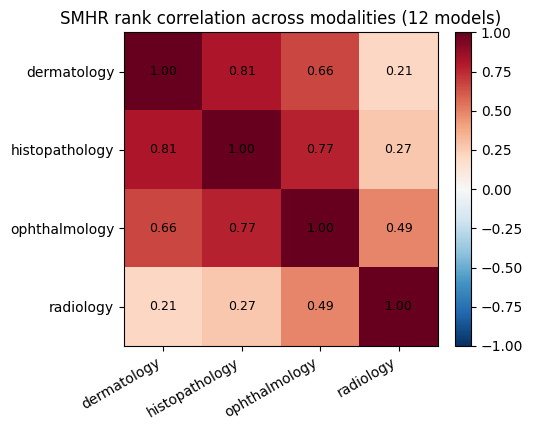

,modality_a,modality_b,n_models,spearman_r,significance
0,dermatology,histopathology,12,0.811,significant (p<0.05)
1,dermatology,ophthalmology,12,0.664,significant (p<0.05)
2,dermatology,radiology,12,0.210,not significant (p>=0.05)
3,histopathology,ophthalmology,12,0.769,significant (p<0.05)
4,histopathology,radiology,12,0.273,not significant (p>=0.05)
5,ophthalmology,radiology,12,0.490,not significant (p>=0.05)


**SRI cross-modal correlation, specialists only (n = 3)**

,modality_a,modality_b,spearman_r,significance
0,dermatology,histopathology,1.000,significant (perfect correlation)
1,dermatology,ophthalmology,0.500,not significant (p>=0.05)
2,dermatology,radiology,0.500,not significant (p>=0.05)
3,histopathology,ophthalmology,0.500,not significant (p>=0.05)
4,histopathology,radiology,0.500,not significant (p>=0.05)
5,ophthalmology,radiology,-0.500,not significant (p>=0.05)


In [5]:
pe = load('pillar_e_cross_modal_transfer.json')
mods = pe['modalities']
mat = pd.DataFrame(np.eye(len(mods)), index=mods, columns=mods)
for r in pe['smhr_cross_modal_correlation']:
    mat.loc[r['modality_a'], r['modality_b']] = r['spearman_r']
    mat.loc[r['modality_b'], r['modality_a']] = r['spearman_r']

fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(mat.values, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(mods))); ax.set_xticklabels(mods, rotation=30, ha='right')
ax.set_yticks(range(len(mods))); ax.set_yticklabels(mods)
for i in range(len(mods)):
    for j in range(len(mods)):
        ax.text(j, i, f'{mat.values[i, j]:.2f}', ha='center', va='center', fontsize=9)
ax.set_title('SMHR rank correlation across modalities (12 models)')
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

pairs = pd.DataFrame(pe['smhr_cross_modal_correlation'])[['modality_a', 'modality_b', 'n_models', 'spearman_r', 'significance']]
display(pairs)
display(Markdown('**SRI cross-modal correlation, specialists only (n = 3)**'))
display(pd.DataFrame(pe['sri_cross_modal_correlation_specialists_only'])[['modality_a', 'modality_b', 'spearman_r', 'significance']])

## 4. Pillar D (RQ10): calibration robustness

**Design.** 5 models (qwen25vl, llava16, chexagent, huatuogpt, llava_med) x 6 decoding configs
(temperature {0.0, 0.3, 0.7} x {greedy, nucleus top-p 0.9}) x 1,679 calls = 50,370 calls on a 500-image subset.
Greedy decoding ignores temperature, so the three greedy configs are identical for four of the five models:
only **four decoding settings are independent**.

**Data-integrity note.** A 220-token cap added mid-run truncated 6,299 llava16 Q1/Q3/Q4 responses. They were
excluded and the 5,361 Q1/Q3 calls regenerated uncapped (`pillar_d_llava16_uncapped.jsonl`); Q4 is dropped
because no model states a confidence on Q4.

**Label.** A response is *correct* iff it has zero Class 1-7 hallucinations (strict: Layer 2 claim judgments plus
Layer 1 omissions). A claim-level-only variant is the sensitivity check. ECE = 10 equal-width bins; ACE = 10
equal-mass bins.

In [6]:
if RERUN_CPU_ANALYSES:
    for script in (['stage3_pd_ece.py', '--boot', '500'], ['stage3_pd_robustness.py']):
        subprocess.run([sys.executable] + script, cwd=ROOT, check=True)
else:
    print('Reading saved results (set RERUN_CPU_ANALYSES = True in the setup cell to recompute).')

pd_res = load('pillar_d_calibration_results.json')
CONFIGS = ['temp0.0_greedy', 'temp0.0_nucleus', 'temp0.3_greedy', 'temp0.3_nucleus', 'temp0.7_greedy', 'temp0.7_nucleus']
MODELS = ['qwen25vl', 'llava16', 'chexagent', 'huatuogpt', 'llava_med']

def cell_table(label, field):
    return pd.DataFrame({c: {m: pd_res['cells'].get(f'{m}|{c}', {}).get(label, {}).get(field) for m in MODELS}
                         for c in CONFIGS})

for label in ('strict', 'claims'):
    display(Markdown(f'**ECE, {label} label**'));  display(cell_table(label, 'ece'))
    display(Markdown(f'**ACE, {label} label**'));  display(cell_table(label, 'ace'))
display(Markdown('**n (responses with a stated confidence and a label), strict**')); display(cell_table('strict', 'n'))
display(Markdown('**Accuracy under the strict label** (fraction with zero Class 1-7 hallucinations)')); display(cell_table('strict', 'accuracy'))
mc = pd.DataFrame({c: {m: pd_res['cells'].get(f'{m}|{c}', {}).get('mean_conf') for m in MODELS} for c in CONFIGS})
display(Markdown('**Mean stated confidence**')); display(mc)
cov = pd.DataFrame({c: {m: (lambda v: v['with_conf'] / v['total'])(pd_res['cells'][f'{m}|{c}']['coverage']) for m in MODELS} for c in CONFIGS})
display(Markdown('**Coverage: share of calls that state a confidence**')); display(cov)

Reading saved results (set RERUN_CPU_ANALYSES = True in the setup cell to recompute).


**ECE, strict label**

,temp0.0_greedy,temp0.0_nucleus,temp0.3_greedy,temp0.3_nucleus,temp0.7_greedy,temp0.7_nucleus
qwen25vl,0.666,0.677,0.666,0.661,0.666,0.651
llava16,0.549,0.503,0.549,0.595,0.549,0.589
chexagent,0.508,0.528,0.508,0.533,0.508,0.547
huatuogpt,0.693,0.706,0.693,0.717,0.693,0.730
llava_med,0.673,0.674,0.673,0.672,0.673,0.669


**ACE, strict label**

,temp0.0_greedy,temp0.0_nucleus,temp0.3_greedy,temp0.3_nucleus,temp0.7_greedy,temp0.7_nucleus
qwen25vl,0.665,0.676,0.665,0.661,0.665,0.649
llava16,0.542,0.502,0.542,0.585,0.542,0.586
chexagent,0.508,0.528,0.508,0.531,0.508,0.547
huatuogpt,0.693,0.706,0.693,0.717,0.693,0.726
llava_med,0.673,0.674,0.673,0.668,0.673,0.662


...

,temp0.0_greedy,temp0.0_nucleus,temp0.3_greedy,temp0.3_nucleus,temp0.7_greedy,temp0.7_nucleus
qwen25vl,0.138,0.140,0.138,0.149,0.138,0.138
llava16,0.193,0.222,0.193,0.225,0.193,0.218
chexagent,0.284,0.250,0.284,0.228,0.284,0.204
huatuogpt,0.124,0.132,0.124,0.151,0.124,0.142
llava_med,0.234,0.232,0.234,0.227,0.234,0.222


**Mean stated confidence**

,temp0.0_greedy,temp0.0_nucleus,temp0.3_greedy,temp0.3_nucleus,temp0.7_greedy,temp0.7_nucleus
qwen25vl,0.798,0.809,0.798,0.810,0.798,0.787
llava16,0.575,0.518,0.575,0.667,0.575,0.703
chexagent,0.541,0.627,0.541,0.593,0.541,0.625
huatuogpt,0.817,0.838,0.817,0.868,0.817,0.868
llava_med,0.906,0.906,0.906,0.894,0.906,0.883


**Coverage: share of calls that state a confidence**

,temp0.0_greedy,temp0.0_nucleus,temp0.3_greedy,temp0.3_nucleus,temp0.7_greedy,temp0.7_nucleus
qwen25vl,0.891,0.896,0.891,0.886,0.891,0.879
llava16,0.721,0.689,0.787,0.691,0.787,0.692
chexagent,0.834,0.841,0.834,0.815,0.834,0.700
huatuogpt,0.816,0.787,0.816,0.756,0.816,0.721
llava_med,0.474,0.475,0.474,0.477,0.474,0.417


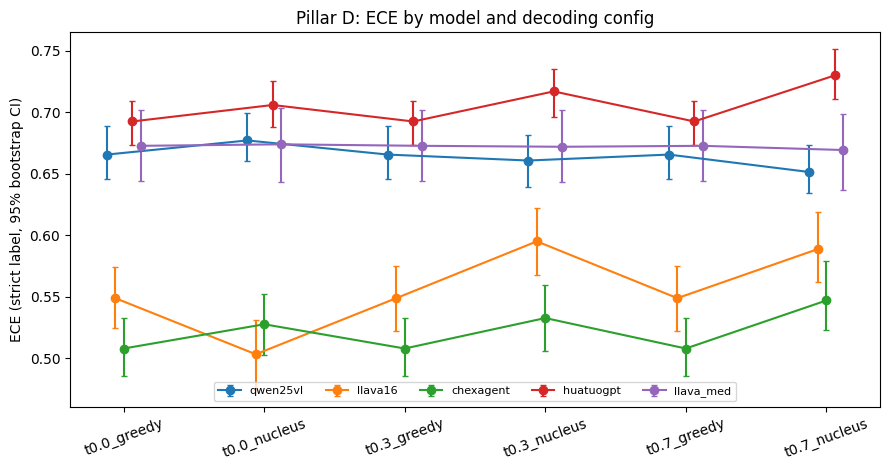

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(CONFIGS))
for i, m in enumerate(MODELS):
    ys, lo, hi = [], [], []
    for c in CONFIGS:
        s = pd_res['cells'].get(f'{m}|{c}', {}).get('strict', {})
        ys.append(s.get('ece', np.nan))
        ci = s.get('ece_ci95', [np.nan, np.nan])
        lo.append(s.get('ece', np.nan) - ci[0]); hi.append(ci[1] - s.get('ece', np.nan))
    ax.errorbar(x + (i - 2) * 0.06, ys, yerr=[lo, hi], marker='o', capsize=2, label=m)
ax.set_xticks(x); ax.set_xticklabels([c.replace('temp', 't') for c in CONFIGS], rotation=20)
ax.set_ylabel('ECE (strict label, 95% bootstrap CI)')
ax.set_title('Pillar D: ECE by model and decoding config')
ax.legend(ncol=5, fontsize=8, loc='lower center'); plt.tight_layout(); plt.show()

In [8]:
rows = []
for label in ('strict', 'claims'):
    for key, st in pd_res['rank_stability'][label].items():
        if st:
            rows.append({'label': label, 'models / configs': key, 'mean rho': st['mean_rho'], 'min rho': st['min_rho'],
                         'verdict': st['verdict']})
display(Markdown('**Rank stability** (mean pairwise Spearman rho of the models\' ECE rankings across configs)'))
display(pd.DataFrame(rows))

st = pd_res['rank_stability']['strict']['all_6_configs']
display(Markdown('**Model ranking by ECE per config (best to worst), strict label**'))
display(pd.DataFrame({c: pd.Series(r) for c, r in st['rankings'].items()}))

**Rank stability** (mean pairwise Spearman rho of the models' ECE rankings across configs)

,label,models / configs,mean rho,min rho,verdict
0,strict,all_6_configs,0.933,0.800,STABLE -- calibration ranking is a weights pro...
1,strict,distinct_4_settings,0.900,0.800,STABLE -- calibration ranking is a weights pro...
2,strict,all_6_configs_excl_llava16,0.933,0.800,STABLE -- calibration ranking is a weights pro...
3,strict,distinct_4_settings_excl_llava16,0.900,0.800,STABLE -- calibration ranking is a weights pro...
4,claims,all_6_configs,0.807,0.600,STABLE -- calibration ranking is a weights pro...
5,claims,distinct_4_settings,0.750,0.600,PARTIALLY STABLE -- inconclusive (0.4 < mean r...
6,claims,all_6_configs_excl_llava16,0.893,0.800,STABLE -- calibration ranking is a weights pro...
7,claims,distinct_4_settings_excl_llava16,0.867,0.800,STABLE -- calibration ranking is a weights pro...


**Model ranking by ECE per config (best to worst), strict label**

,temp0.0_greedy,temp0.0_nucleus,temp0.3_greedy,temp0.3_nucleus,temp0.7_greedy,temp0.7_nucleus
0,chexagent,llava16,chexagent,chexagent,chexagent,chexagent
1,llava16,chexagent,llava16,llava16,llava16,llava16
2,qwen25vl,llava_med,qwen25vl,qwen25vl,qwen25vl,qwen25vl
3,llava_med,qwen25vl,llava_med,llava_med,llava_med,llava_med
4,huatuogpt,huatuogpt,huatuogpt,huatuogpt,huatuogpt,huatuogpt


### Robustness checks
Alternative binning, per-modality analysis, a common-coverage subset (items where all five models stated a
confidence), a label-noise simulation (random flips, one draw per distinct response, 200 repetitions), and
leave-one-model-out. All use the strict label.

In [9]:
rb = load('pillar_d_robustness.json')

def rho_row(s):
    return {k: (f"{v['mean_rho']:.2f} (min {v['min_rho']:.2f})" if v else 'n/a') for k, v in s.items()}

display(Markdown('**A. ECE bin count**'))
display(pd.DataFrame({f'{k} bins': rho_row(v) for k, v in rb['A_bins'].items()}).T)

display(Markdown('**B. By modality** (rho across configs, plus ECE at greedy)'))
tab = {}
for mod, d in rb['B_modality'].items():
    tab[mod] = {**rho_row(d['rho']), **{f'ECE {m}': v for m, v in d['ece_greedy'].items()}}
display(pd.DataFrame(tab).T)

display(Markdown('**C. Common-coverage subset**'))
display(pd.DataFrame([{'items per config': rb['C_common_coverage']['n_items_per_config'], **rho_row(rb['C_common_coverage']['rho'])}]))

display(Markdown('**D. Label-noise simulation** (flip probability -> mean rho, 5th percentile, P[rho >= 0.8])'))
nrows = [{'flip rate': 'baseline', **{k: f"{v['mean_rho']:.2f}" for k, v in rb['D_noise']['baseline'].items() if v}}]
for p in ('0.05', '0.13', '0.2'):
    d = rb['D_noise'][p]
    nrows.append({'flip rate': p, **{k: f"{v['mean']:.2f} (p5 {v['p05']:.2f}, P>=0.8: {v['frac_ge_0.8']:.2f})" for k, v in d.items()}})
display(pd.DataFrame(nrows))

display(Markdown('**E. Leave-one-model-out**'))
display(pd.DataFrame({f'without {m}': rho_row(v) for m, v in rb['E_leave_one_out'].items()}).T)

**A. ECE bin count**

,all6,distinct4
5 bins,0.93 (min 0.80),0.90 (min 0.80)
10 bins,0.93 (min 0.80),0.90 (min 0.80)
15 bins,0.93 (min 0.80),0.90 (min 0.80)
20 bins,0.93 (min 0.80),0.90 (min 0.80)


**B. By modality** (rho across configs, plus ECE at greedy)

,all6,distinct4,ECE qwen25vl,ECE llava16,ECE chexagent,ECE huatuogpt,ECE llava_med
radiology,0.81 (min 0.60),0.75 (min 0.60),0.895,0.612,0.364,0.703,0.792
dermatology,0.74 (min 0.50),0.65 (min 0.50),0.587,0.496,0.569,0.632,0.612
histopathology,0.97 (min 0.90),0.95 (min 0.90),0.694,0.540,0.661,0.751,0.398
ophthalmology,0.97 (min 0.90),0.95 (min 0.90),0.286,0.470,0.521,0.701,0.893


**C. Common-coverage subset**

,items per config,all6,distinct4
0,"{'temp0.0_greedy': 537, 'temp0.0_nucleus': 555...",0.81 (min 0.50),0.75 (min 0.50)


**D. Label-noise simulation** (flip probability -> mean rho, 5th percentile, P[rho >= 0.8])

,flip rate,all6,distinct4
0,baseline,0.93,0.90
1,0.05,"0.93 (p5 0.85, P>=0.8: 0.99)","0.91 (p5 0.83, P>=0.8: 0.99)"
2,0.13,"0.85 (p5 0.73, P>=0.8: 0.70)","0.82 (p5 0.70, P>=0.8: 0.52)"
3,0.2,"0.78 (p5 0.60, P>=0.8: 0.39)","0.72 (p5 0.53, P>=0.8: 0.15)"


**E. Leave-one-model-out**

,all6,distinct4
without qwen25vl,0.93 (min 0.80),0.90 (min 0.80)
without llava16,0.93 (min 0.80),0.90 (min 0.80)
without chexagent,0.93 (min 0.80),0.90 (min 0.80)
without huatuogpt,0.87 (min 0.60),0.80 (min 0.60)
without llava_med,0.93 (min 0.80),0.90 (min 0.80)


### Pillar D verdict
For the strict label the ECE ranking is stable across decoding settings (mean rho 0.90-0.93), consistent with
calibration being primarily a **weights property**. Support is moderate rather than high: the result is robust to
binning and to dropping individual models, holds within histopathology and ophthalmology, but weakens in
radiology and dermatology, on the common-coverage subset (rho about 0.75-0.81), under the claim-level label, and
under label noise above about 10%. ECE here mostly reflects overconfidence (accuracy 12-28% against 54-91% mean
stated confidence), and per-model orderings differ by modality, so pooled ECE is not one number per model.
Full write-up: `medvihall_outputs/pillar_d_results_section.md`.

## 5. Reproducing the pipeline

Run from the project root. Every stage is resume-safe (it rescans its output file on start).

| Stage | Command | Needs GPU |
|---|---|---|
| Pillar D generation (5 models x 6 configs, one model at a time) | `python stage2_pillar_d_calibration.py` | yes, about 10 days |
| llava16 uncapped regeneration | `python stage2_pillar_d_llava16_regen.py` | yes, about 1.5 days |
| Stage 3 labeling (claims -> Layer 1 -> Layer 2) | `python stage3_pd_label.py all` | yes, about 12 hours |
| ECE/ACE + rank stability | `python stage3_pd_ece.py --boot 500` | no |
| Robustness checks | `python stage3_pd_robustness.py` | no |

Notes: run only one GPU model at a time (two concurrent 7B models collapse VRAM on a 16 GB card); the Layer 1
non-radiology step runs under Python 3.12 (scispaCy); long jobs are better launched from your own terminal.